In [3]:
# --- Celda 1: descarga (ejecutar una vez) ---
!git clone --depth 1 https://github.com/spMohanty/PlantVillage-Dataset.git
# --- Celda 2: entrenamiento ---
import random
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", device)

DATASET_DIR = "PlantVillage-Dataset/raw/color"
PLANT = "Tomato"
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
val_tf = transforms.Compose([  # sin augmentation
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

ds_train = datasets.ImageFolder(DATASET_DIR, transform=train_tf)
ds_val = datasets.ImageFolder(DATASET_DIR, transform=val_tf)

# Solo clases del cultivo elegido, con etiquetas reindexadas 0..N-1
class_names = [c for c in ds_train.classes if PLANT in c]
old2new = {ds_train.class_to_idx[c]: i for i, c in enumerate(class_names)}
ds_train.target_transform = old2new.__getitem__
ds_val.target_transform = old2new.__getitem__

selected = [i for i, (_, y) in enumerate(ds_train.samples) if y in old2new]
random.shuffle(selected)
cut = int(0.8 * len(selected))
train_idx, val_idx = selected[:cut], selected[cut:]

train_loader = DataLoader(Subset(ds_train, train_idx), batch_size=32,
                          shuffle=True, num_workers=2)
val_loader = DataLoader(Subset(ds_val, val_idx), batch_size=32,
                        shuffle=False, num_workers=2)

print(f"Clases ({len(class_names)}):", *class_names, sep="\n  - ")
print(f"Entrenamiento: {len(train_idx)} | Validación: {len(val_idx)}")

# Modelo
model = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)
for p in model.features.parameters():
    p.requires_grad = False
model.classifier[1] = nn.Linear(model.classifier[1].in_features, len(class_names))
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.classifier.parameters(), lr=0.001)

def run_epoch(loader, train):
    model.train() if train else model.eval()
    if train:
        model.features.eval()  # mantiene fijo el BatchNorm del backbone
    loss_sum, correct, total = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            if train:
                optimizer.zero_grad()
            out = model(x)
            loss = criterion(out, y)
            if train:
                loss.backward()
                optimizer.step()
            loss_sum += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            total += y.size(0)
    return loss_sum / total, correct / total

EPOCHS = 3
for epoch in range(EPOCHS):
    tr_loss, tr_acc = run_epoch(train_loader, train=True)
    va_loss, va_acc = run_epoch(val_loader, train=False)
    print(f"Época {epoch+1}/{EPOCHS} | train: {tr_loss:.4f} / {tr_acc:.4f} "
          f"| val: {va_loss:.4f} / {va_acc:.4f}")

# Guardar pesos + nombres de clases
torch.save({
    "state_dict": model.state_dict(),
    "class_names": class_names,
    "arch": "mobilenet_v2",
    "input_size": 224,
}, "dalia_tomato_mobilenetv2.pth")
print("Guardado: dalia_tomato_mobilenetv2.pth")



fatal: destination path 'PlantVillage-Dataset' already exists and is not an empty directory.
Dispositivo: cuda
Clases (10):
  - Tomato___Bacterial_spot
  - Tomato___Early_blight
  - Tomato___Late_blight
  - Tomato___Leaf_Mold
  - Tomato___Septoria_leaf_spot
  - Tomato___Spider_mites Two-spotted_spider_mite
  - Tomato___Target_Spot
  - Tomato___Tomato_Yellow_Leaf_Curl_Virus
  - Tomato___Tomato_mosaic_virus
  - Tomato___healthy
Entrenamiento: 14528 | Validación: 3632
Época 1/3 | train: 0.8669 / 0.7609 | val: 0.5409 / 0.8599
Época 2/3 | train: 0.4523 / 0.8762 | val: 0.3999 / 0.8874
Época 3/3 | train: 0.3549 / 0.9009 | val: 0.3323 / 0.9053
Guardado: dalia_tomato_mobilenetv2.pth


In [ ]:
from google.colab import files
files.download("dalia_tomato_mobilenetv2.pth")

In [5]:
from sklearn.metrics import classification_report, confusion_matrix

short = [c.replace("Tomato___", "") for c in class_names]
model.eval()
y_true, y_pred = [], []
with torch.no_grad():
    for x, y in val_loader:
        out = model(x.to(device))
        y_pred.extend(out.argmax(1).cpu().tolist())
        y_true.extend(y.tolist())

print(classification_report(y_true, y_pred, target_names=short, digits=3))
print(confusion_matrix(y_true, y_pred))  # filas = real, columnas = predicho

                                      precision    recall  f1-score   support

                      Bacterial_spot      0.919     0.936     0.928       377
                        Early_blight      0.894     0.652     0.754       221
                         Late_blight      0.904     0.944     0.924       378
                           Leaf_Mold      0.912     0.775     0.838       187
                  Septoria_leaf_spot      0.854     0.880     0.867       333
Spider_mites Two-spotted_spider_mite      0.881     0.871     0.876       357
                         Target_Spot      0.715     0.869     0.784       291
       Tomato_Yellow_Leaf_Curl_Virus      0.976     0.981     0.979      1092
                 Tomato_mosaic_virus      0.942     0.803     0.867        61
                             healthy      0.934     0.931     0.933       335

                            accuracy                          0.905      3632
                           macro avg      0.893     0.864     

In [8]:
from PIL import Image
from google.colab import files

def predict(path, topk=3):
    img = Image.open(path).convert("RGB")
    x = val_tf(img).unsqueeze(0).to(device)
    model.eval()
    with torch.no_grad():
        probs = torch.softmax(model(x), dim=1)[0]
    conf, idx = probs.topk(topk)
    for c, i in zip(conf.tolist(), idx.tolist()):
        print(f"  {short[i]}: {c*100:.1f}%")

uploaded = files.upload()
for name in uploaded:
    print(name)
    predict(name)

Saving tomate enfermo.jpg to tomate enfermo (2).jpg
Saving tomate.jpg to tomate (1).jpg
Saving tomate seco.jpg to tomate seco (1).jpg
Saving tomate sano.jpeg to tomate sano (1).jpeg
tomate enfermo (2).jpg


NameError: name 'val_tf' is not defined

In [7]:
!ls *.pth *.jp*g

'dalia_tomato_mobilenetv2 (1).pth'  'tomate enfermo.jpg'  'tomate sano.jpeg'
'tomate enfermo (1).jpg'	     tomate.jpg		  'tomate seco.jpg'


In [10]:
from google.colab import files
_ = files.upload()

Saving dalia_tomato_mobilenetv2.pth to dalia_tomato_mobilenetv2.pth


In [13]:
import glob
import torch
import torch.nn as nn
from torchvision import models, transforms
from PIL import Image
from google.colab import files

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

ckpt = torch.load("dalia_tomato_mobilenetv2.pth", map_location=device, weights_only=True)
class_names = ckpt["class_names"]
short = [c.replace("Tomato___", "") for c in class_names]

model = models.mobilenet_v2(weights=None)
model.classifier[1] = nn.Linear(model.classifier[1].in_features, len(class_names))
model.load_state_dict(ckpt["state_dict"])
model = model.to(device).eval()

val_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

def predict(path, topk=3):
    img = Image.open(path).convert("RGB")
    x = val_tf(img).unsqueeze(0).to(device)
    with torch.no_grad():
        probs = torch.softmax(model(x), dim=1)[0]
    conf, idx = probs.topk(topk)
    for c, i in zip(conf.tolist(), idx.tolist()):
        print(f"  {short[i]}: {c*100:.1f}%")

for name in sorted(glob.glob("*.jp*g")):
    print(name)
    predict(name)

tomate (1).jpg
  Late_blight: 56.4%
  Early_blight: 17.6%
  healthy: 14.8%
tomate enfermo (1).jpg
  Early_blight: 50.0%
  Septoria_leaf_spot: 34.4%
  Late_blight: 15.4%
tomate enfermo (2).jpg
  Early_blight: 50.0%
  Septoria_leaf_spot: 34.4%
  Late_blight: 15.4%
tomate enfermo.jpg
  Early_blight: 50.0%
  Septoria_leaf_spot: 34.4%
  Late_blight: 15.4%
tomate sano (1).jpeg
  Late_blight: 93.2%
  Early_blight: 4.4%
  Tomato_Yellow_Leaf_Curl_Virus: 0.7%
tomate sano.jpeg
  Late_blight: 93.2%
  Early_blight: 4.4%
  Tomato_Yellow_Leaf_Curl_Virus: 0.7%
tomate seco (1).jpg
  Late_blight: 87.6%
  Early_blight: 11.8%
  Bacterial_spot: 0.3%
tomate seco.jpg
  Late_blight: 87.6%
  Early_blight: 11.8%
  Bacterial_spot: 0.3%
tomate.jpg
  Late_blight: 56.4%
  Early_blight: 17.6%
  healthy: 14.8%


In [15]:
import glob
import torch
import torch.nn as nn
from torchvision import models, transforms
from PIL import Image
from google.colab import files

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

ckpt = torch.load("dalia_tomato_mobilenetv2.pth", map_location=device, weights_only=True)
class_names = ckpt["class_names"]
short = [c.replace("Tomato___", "") for c in class_names]

model = models.mobilenet_v2(weights=None)
model.classifier[1] = nn.Linear(model.classifier[1].in_features, len(class_names))
model.load_state_dict(ckpt["state_dict"])
model = model.to(device).eval()

val_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

def predict(path, topk=3):
    img = Image.open(path).convert("RGB")
    x = val_tf(img).unsqueeze(0).to(device)
    with torch.no_grad():
        probs = torch.softmax(model(x), dim=1)[0]
    conf, idx = probs.topk(topk)
    for c, i in zip(conf.tolist(), idx.tolist()):
        print(f"  {short[i]}: {c*100:.1f}%")

for name in sorted(glob.glob("*.jp*g")):
    print(name)
    predict(name)

tomate (1).jpg
  Late_blight: 56.4%
  Early_blight: 17.6%
  healthy: 14.8%
tomate enfermo (1).jpg
  Early_blight: 50.0%
  Septoria_leaf_spot: 34.4%
  Late_blight: 15.4%
tomate enfermo (2).jpg
  Early_blight: 50.0%
  Septoria_leaf_spot: 34.4%
  Late_blight: 15.4%
tomate enfermo.jpg
  Early_blight: 50.0%
  Septoria_leaf_spot: 34.4%
  Late_blight: 15.4%
tomate sano (1).jpeg
  Late_blight: 93.2%
  Early_blight: 4.4%
  Tomato_Yellow_Leaf_Curl_Virus: 0.7%
tomate sano.jpeg
  Late_blight: 93.2%
  Early_blight: 4.4%
  Tomato_Yellow_Leaf_Curl_Virus: 0.7%
tomate seco (1).jpg
  Late_blight: 87.6%
  Early_blight: 11.8%
  Bacterial_spot: 0.3%
tomate seco.jpg
  Late_blight: 87.6%
  Early_blight: 11.8%
  Bacterial_spot: 0.3%
tomate.jpg
  Late_blight: 56.4%
  Early_blight: 17.6%
  healthy: 14.8%


In [16]:
uploaded = files.upload()
for name in uploaded:
    print(name)
    predict(name)

Saving hoja de tomate manchas.jpg to hoja de tomate manchas.jpg
Saving hoja de tomate enfermo.jpg to hoja de tomate enfermo.jpg
Saving hoja de tomate sano.jpg to hoja de tomate sano.jpg
Saving hoja de tomate manchada.jpg to hoja de tomate manchada.jpg
Saving hojas de tomate sano.webp to hojas de tomate sano.webp
Saving tomate muerto.jpg to tomate muerto.jpg
hoja de tomate manchas.jpg
  Late_blight: 53.5%
  Septoria_leaf_spot: 25.3%
  Early_blight: 6.7%
hoja de tomate enfermo.jpg
  Septoria_leaf_spot: 83.7%
  Early_blight: 15.7%
  Bacterial_spot: 0.3%
hoja de tomate sano.jpg
  Late_blight: 82.1%
  Septoria_leaf_spot: 11.2%
  Early_blight: 2.9%
hoja de tomate manchada.jpg
  Early_blight: 50.6%
  Tomato_Yellow_Leaf_Curl_Virus: 16.4%
  Septoria_leaf_spot: 13.0%
hojas de tomate sano.webp
  Late_blight: 59.3%
  Septoria_leaf_spot: 23.3%
  healthy: 11.2%
tomate muerto.jpg
  Late_blight: 61.1%
  Early_blight: 30.8%
  Tomato_Yellow_Leaf_Curl_Virus: 4.7%


DALia v2

Descarga de datasets Plantvillage y PlantDoc

In [17]:
!test -d PlantVillage-Dataset || git clone --depth 1 https://github.com/spMohanty/PlantVillage-Dataset.git
!test -d PlantDoc-Dataset || git clone --depth 1 https://github.com/pratikkayal/PlantDoc-Dataset.git

Cloning into 'PlantVillage-Dataset'...
remote: Enumerating objects: 163219, done.
remote: Counting objects: 100% (163219/163219), done.
remote: Compressing objects: 100% (163125/163125), done.
remote: Total 163219 (delta 93), reused 163215 (delta 93), pack-reused 0 (from 0)
Receiving objects: 100% (163219/163219), 2.00 GiB | 23.57 MiB/s, done.
Resolving deltas: 100% (93/93), done.
Updating files: 100% (182404/182404), done.
Cloning into 'PlantDoc-Dataset'...
remote: Enumerating objects: 2628, done.
remote: Counting objects: 100% (2628/2628), done.
remote: Compressing objects: 100% (2627/2627), done.
remote: Total 2628 (delta 1), reused 2616 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (2628/2628), 932.91 MiB | 23.04 MiB/s, done.
Resolving deltas: 100% (1/1), done.
Updating files: 100% (2581/2581), done.


Datos

In [18]:
import os, random
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", device)

DATASET_DIR = "PlantVillage-Dataset/raw/color"
PLANT = "Tomato"
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.4, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(30),
    transforms.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.4, hue=0.05),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
    transforms.RandomErasing(p=0.25),
])
val_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

ds_train = datasets.ImageFolder(DATASET_DIR, transform=train_tf)
ds_val = datasets.ImageFolder(DATASET_DIR, transform=val_tf)

class_names = [c for c in ds_train.classes if PLANT in c]
old2new = {ds_train.class_to_idx[c]: i for i, c in enumerate(class_names)}
ds_train.target_transform = old2new.__getitem__
ds_val.target_transform = old2new.__getitem__

selected = [i for i, (_, y) in enumerate(ds_train.samples) if y in old2new]
random.shuffle(selected)
cut = int(0.8 * len(selected))
train_idx, val_idx = selected[:cut], selected[cut:]

train_loader = DataLoader(Subset(ds_train, train_idx), batch_size=32,
                          shuffle=True, num_workers=2)
val_loader = DataLoader(Subset(ds_val, val_idx), batch_size=32,
                        shuffle=False, num_workers=2)

# Pesos por clase (las clases con pocas imágenes pesan más)
counts = torch.zeros(len(class_names))
for i in train_idx:
    counts[old2new[ds_train.samples[i][1]]] += 1
class_weights = (counts.sum() / (len(class_names) * counts)).to(device)

print(f"Clases: {len(class_names)} | Entrenamiento: {len(train_idx)} | Validación: {len(val_idx)}")

Dispositivo: cuda
Clases: 10 | Entrenamiento: 14528 | Validación: 3632


Modelo y entrenamiento

In [19]:
UNFREEZE_FROM = 14   # bloques finales de MobileNetV2 que se ajustan
EPOCHS = 8
USE_CLASS_WEIGHTS = True

model = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)
for p in model.features.parameters():
    p.requires_grad = False
for p in model.features[UNFREEZE_FROM:].parameters():
    p.requires_grad = True
model.classifier[1] = nn.Linear(model.classifier[1].in_features, len(class_names))
model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights if USE_CLASS_WEIGHTS else None)
optimizer = optim.Adam([
    {"params": model.features[UNFREEZE_FROM:].parameters(), "lr": 1e-4},
    {"params": model.classifier.parameters(), "lr": 1e-3},
])
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

def run_epoch(loader, train):
    model.train() if train else model.eval()
    if train:
        model.features[:UNFREEZE_FROM].eval()  # BatchNorm fijo en las capas congeladas
    loss_sum, correct, total = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            if train:
                optimizer.zero_grad()
            out = model(x)
            loss = criterion(out, y)
            if train:
                loss.backward()
                optimizer.step()
            loss_sum += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            total += y.size(0)
    return loss_sum / total, correct / total

best = 0.0
for epoch in range(EPOCHS):
    tr_loss, tr_acc = run_epoch(train_loader, train=True)
    va_loss, va_acc = run_epoch(val_loader, train=False)
    scheduler.step()
    print(f"Época {epoch+1}/{EPOCHS} | train: {tr_loss:.4f} / {tr_acc:.4f} "
          f"| val: {va_loss:.4f} / {va_acc:.4f}")
    if va_acc > best:
        best = va_acc
        torch.save({
            "state_dict": model.state_dict(),
            "class_names": class_names,
            "arch": "mobilenet_v2",
            "input_size": 224,
            "version": "v2a",
        }, "dalia_tomato_v2.pth")
        print("  -> guardado dalia_tomato_v2.pth")

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 100MB/s] 


Época 1/8 | train: 0.6629 / 0.8246 | val: 0.2138 / 0.9408
  -> guardado dalia_tomato_v2.pth
Época 2/8 | train: 0.2694 / 0.9177 | val: 0.1347 / 0.9637
  -> guardado dalia_tomato_v2.pth
Época 3/8 | train: 0.2162 / 0.9356 | val: 0.1022 / 0.9648
  -> guardado dalia_tomato_v2.pth
Época 4/8 | train: 0.1680 / 0.9472 | val: 0.0783 / 0.9758
  -> guardado dalia_tomato_v2.pth
Época 5/8 | train: 0.1473 / 0.9561 | val: 0.0732 / 0.9760
  -> guardado dalia_tomato_v2.pth
Época 6/8 | train: 0.1335 / 0.9595 | val: 0.0705 / 0.9771
  -> guardado dalia_tomato_v2.pth
Época 7/8 | train: 0.1210 / 0.9610 | val: 0.0706 / 0.9769
Época 8/8 | train: 0.1228 / 0.9626 | val: 0.0679 / 0.9760


In [20]:
from google.colab import files
files.download("dalia_tomato_v2.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Pruebas Celda 5

In [ ]:
import glob
from PIL import Image
from google.colab import files

ckpt = torch.load("dalia_tomato_v2b.pth", map_location=device, weights_only=True)
class_names = ckpt["class_names"]
short = [c.replace("Tomato___", "") for c in class_names]

net = models.mobilenet_v2(weights=None)
net.classifier[1] = nn.Linear(net.classifier[1].in_features, len(class_names))
net.load_state_dict(ckpt["state_dict"])
net = net.to(device).eval()

eval_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

def predict(path, topk=3):
    img = Image.open(path).convert("RGB")
    x = eval_tf(img).unsqueeze(0).to(device)
    with torch.no_grad():
        probs = torch.softmax(net(x), dim=1)[0]
    conf, idx = probs.topk(topk)
    for c, i in zip(conf.tolist(), idx.tolist()):
        print(f"  {short[i]}: {c*100:.1f}%")

#files.upload()   #quita el # para subir fotos nuevas
for name in sorted(glob.glob("*.jp*g") + glob.glob("*.webp")):
    if "(" in name:   # omite duplicados como "tomate (1).jpg"
        continue
    print(name)
    predict(name)

In [26]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
norm = transforms.Compose([transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

def v_estirar(img):   # lo que usamos hasta ahora
    return norm(transforms.Resize((224, 224))(img))

def v_recorte(img):   # lado corto a 256 y recorte central
    return norm(transforms.CenterCrop(224)(transforms.Resize(256)(img)))

def v_relleno(img):   # cuadrado con borde gris, sin deformar
    w, h = img.size
    s = max(w, h)
    canvas = Image.new("RGB", (s, s), (128, 128, 128))
    canvas.paste(img, ((s - w) // 2, (s - h) // 2))
    return norm(transforms.Resize((224, 224))(canvas))

i_healthy = class_names.index("Tomato___healthy")

def resumen(x):
    with torch.no_grad():
        p = torch.softmax(net(x.unsqueeze(0).to(device)), dim=1)[0]
    c, i = p.max(0)
    return f"{short[i]} {c.item()*100:.0f}% | healthy {p[i_healthy].item()*100:.1f}%"

for name in sorted(glob.glob("*.jp*g") + glob.glob("*.webp")):
    if "(" in name:
        continue
    img = Image.open(name).convert("RGB")
    print(name)
    print("  estirar:", resumen(v_estirar(img)))
    print("  recorte:", resumen(v_recorte(img)))
    print("  relleno:", resumen(v_relleno(img)))

hoja de tomate enfermo.jpg
  estirar: Septoria_leaf_spot 58% | healthy 0.0%
  recorte: Early_blight 64% | healthy 0.0%
  relleno: Septoria_leaf_spot 85% | healthy 0.0%
hoja de tomate manchada.jpg
  estirar: Septoria_leaf_spot 83% | healthy 0.0%
  recorte: Septoria_leaf_spot 100% | healthy 0.0%
  relleno: Septoria_leaf_spot 76% | healthy 0.0%
hoja de tomate manchas.jpg
  estirar: Late_blight 68% | healthy 0.0%
  recorte: Late_blight 74% | healthy 0.0%
  relleno: Late_blight 60% | healthy 0.0%
hoja de tomate sano.jpg
  estirar: Late_blight 88% | healthy 0.0%
  recorte: Late_blight 98% | healthy 0.1%
  relleno: Late_blight 87% | healthy 0.1%
hojas de tomate sano.webp
  estirar: Late_blight 85% | healthy 0.2%
  recorte: Late_blight 66% | healthy 0.0%
  relleno: Septoria_leaf_spot 63% | healthy 0.0%
tomate enfermo.jpg
  estirar: Early_blight 96% | healthy 0.0%
  recorte: Early_blight 98% | healthy 0.0%
  relleno: Early_blight 99% | healthy 0.0%
tomate muerto.jpg
  estirar: Bacterial_spot 33

In [27]:
!test -d PlantDoc-Dataset || git clone --depth 1 https://github.com/pratikkayal/PlantDoc-Dataset.git
!ls PlantDoc-Dataset
!ls PlantDoc-Dataset/train | grep -i tomato

LICENSE.txt  PlantDoc_Examples.png  README.md  test  train
Tomato Early blight leaf
Tomato leaf
Tomato leaf bacterial spot
Tomato leaf late blight
Tomato leaf mosaic virus
Tomato leaf yellow virus
Tomato mold leaf
Tomato Septoria leaf spot
Tomato two spotted spider mites leaf


v2 celca 2a

55 imágenes


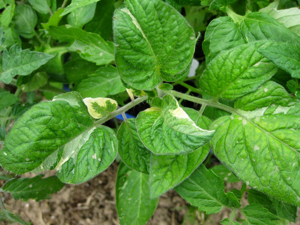

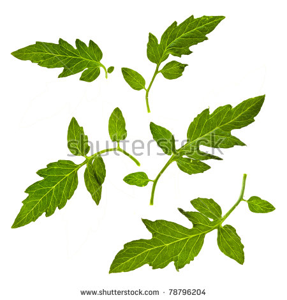

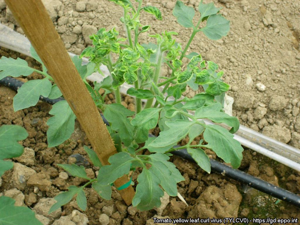

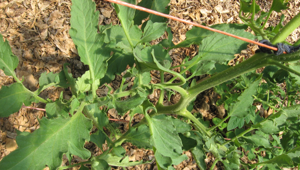

In [29]:
import glob, random
from PIL import Image
from IPython.display import display

fotos = glob.glob("PlantDoc-Dataset/train/Tomato leaf/*")
print(len(fotos), "imágenes")
for f in random.sample(fotos, 4):
    im = Image.open(f).convert("RGB")
    im.thumbnail((300, 300))
    display(im)

v2 celda 2b

In [30]:
from torch.utils.data import ConcatDataset
from sklearn.metrics import classification_report

PD_DIR = "PlantDoc-Dataset"
PD_MAP = {
    "Tomato Early blight leaf": "Tomato___Early_blight",
    "Tomato leaf": "Tomato___healthy",
    "Tomato leaf bacterial spot": "Tomato___Bacterial_spot",
    "Tomato leaf late blight": "Tomato___Late_blight",
    "Tomato leaf mosaic virus": "Tomato___Tomato_mosaic_virus",
    "Tomato leaf yellow virus": "Tomato___Tomato_Yellow_Leaf_Curl_Virus",
    "Tomato mold leaf": "Tomato___Leaf_Mold",
    "Tomato Septoria leaf spot": "Tomato___Septoria_leaf_spot",
    "Tomato two spotted spider mites leaf": "Tomato___Spider_mites Two-spotted_spider_mite",
}
assert all(v in class_names for v in PD_MAP.values()), "Revisa los nombres de clase"

def make_pd(split, tf):
    ds = datasets.ImageFolder(f"{PD_DIR}/{split}", transform=tf)
    m = {ds.class_to_idx[k]: class_names.index(v)
         for k, v in PD_MAP.items() if k in ds.class_to_idx}
    ds.target_transform = m.__getitem__
    keep = [i for i, (_, y) in enumerate(ds.samples) if y in m]
    return ds, keep, m

pd_train_ds, pd_train_keep, pd_train_map = make_pd("train", train_tf)
pd_test_ds, pd_test_keep, _ = make_pd("test", val_tf)
pd_train = Subset(pd_train_ds, pd_train_keep)
pd_test = Subset(pd_test_ds, pd_test_keep)
assert len(pd_train) > 0 and len(pd_test) > 0
print("PlantDoc tomate -> train:", len(pd_train), "| test:", len(pd_test))

# PlantDoc es pequeño: se repite para que pese ~30% del tamaño de PlantVillage
pv_train = Subset(ds_train, train_idx)
REPEAT = max(1, min(10, round(0.3 * len(pv_train) / len(pd_train))))
train_ds = ConcatDataset([pv_train] + [pd_train] * REPEAT)
train_loader = DataLoader(train_ds, batch_size=32, shuffle=True, num_workers=2)
pd_test_loader = DataLoader(pd_test, batch_size=32, shuffle=False, num_workers=2)
print(f"PlantDoc se repite x{REPEAT} | imágenes por época: {len(train_ds)}")

# Pesos por clase con los datos combinados
counts = torch.zeros(len(class_names))
for i in train_idx:
    counts[old2new[ds_train.samples[i][1]]] += 1
for i in pd_train_keep:
    counts[pd_train_map[pd_train_ds.samples[i][1]]] += REPEAT
class_weights = (counts.sum() / (len(class_names) * counts)).to(device)

def evaluate(m, loader):
    m.eval()
    y_true, y_pred = [], []
    with torch.no_grad():
        for x, y in loader:
            y_pred += m(x.to(device)).argmax(1).cpu().tolist()
            y_true += y.tolist()
    acc = sum(int(a == b) for a, b in zip(y_true, y_pred)) / len(y_true)
    return acc, y_true, y_pred

acc0, _, _ = evaluate(net, pd_test_loader)   # net = modelo v2a de la celda 5
print(f"Línea base v2a en PlantDoc (test): {acc0:.3f}")

PlantDoc tomate -> train: 677 | test: 69
PlantDoc se repite x6 | imágenes por época: 18590
Línea base v2a en PlantDoc (test): 0.290


Celda 3b: entrenamiento v2b

In [31]:
UNFREEZE_FROM = 14
EPOCHS = 8

model = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)
for p in model.features.parameters():
    p.requires_grad = False
for p in model.features[UNFREEZE_FROM:].parameters():
    p.requires_grad = True
model.classifier[1] = nn.Linear(model.classifier[1].in_features, len(class_names))
model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = optim.Adam([
    {"params": model.features[UNFREEZE_FROM:].parameters(), "lr": 1e-4},
    {"params": model.classifier.parameters(), "lr": 1e-3},
])
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

def train_epoch():
    model.train()
    model.features[:UNFREEZE_FROM].eval()
    loss_sum, correct, total = 0.0, 0, 0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        out = model(x)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()
        loss_sum += loss.item() * x.size(0)
        correct += (out.argmax(1) == y).sum().item()
        total += y.size(0)
    return loss_sum / total, correct / total

for epoch in range(EPOCHS):
    tr_loss, tr_acc = train_epoch()
    pv_acc, _, _ = evaluate(model, val_loader)
    pd_acc, _, _ = evaluate(model, pd_test_loader)
    scheduler.step()
    print(f"Época {epoch+1}/{EPOCHS} | train: {tr_loss:.4f} / {tr_acc:.4f} "
          f"| val PlantVillage: {pv_acc:.4f} | test PlantDoc: {pd_acc:.4f}")

torch.save({
    "state_dict": model.state_dict(),
    "class_names": class_names,
    "arch": "mobilenet_v2",
    "input_size": 224,
    "version": "v2b",
}, "dalia_tomato_v2b.pth")
print("Guardado: dalia_tomato_v2b.pth")

_, yt, yp = evaluate(model, pd_test_loader)
labels = sorted(set(yt))
print(classification_report(yt, yp, labels=labels, digits=3, zero_division=0,
      target_names=[class_names[i].replace("Tomato___", "") for i in labels]))

Época 1/8 | train: 0.8262 / 0.7457 | val PlantVillage: 0.9254 | test PlantDoc: 0.5797
Época 2/8 | train: 0.4396 / 0.8478 | val PlantVillage: 0.9576 | test PlantDoc: 0.5652


KeyboardInterrupt: 

In [32]:
import os
from google.colab import files
for f in ["dalia_tomato_mobilenetv2.pth", "dalia_tomato_v2.pth", "dalia_tomato_v2b.pth"]:
    if os.path.exists(f):
        files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>